## 1. Objetivo y metodología
Se evalúa estacionariedad con Dickey–Fuller aumentado (ADF) sobre entrenamiento exclusivamente, se determina el orden de diferenciación $d$, se comparan al menos seis modelos ARIMA mediante AIC y se generan pronósticos con intervalos del 95 % sobre la prueba temporal. Se evita fuga de información desde prueba.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from pathlib import Path
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(11,4)

## 2. Carga, limpieza y partición cronológica

In [2]:
ruta=("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 57/TempNY.csv")
df=pd.read_csv(ruta)[["Year","Average"]].dropna().sort_values("Year")
df["Year"]=df["Year"].astype(int)
serie=pd.Series(df["Average"].to_numpy(), index=pd.Index(df["Year"],name="Año"),name="Temperatura")
n_train=int(len(serie)*0.90)
train,test=serie.iloc[:n_train],serie.iloc[n_train:]
print(f"Total={len(serie)}, entrenamiento={len(train)} ({train.index.min()}–{train.index.max()}), prueba={len(test)} ({test.index.min()}–{test.index.max()})")
print(serie.describe())

Total=151, entrenamiento=135 (1870–2004), prueba=16 (2005–2020)
count    151.000000
mean      53.997616
std        1.698316
min       49.340000
25%       52.960000
50%       54.020000
75%       55.180000
max       57.310000
Name: Temperatura, dtype: float64


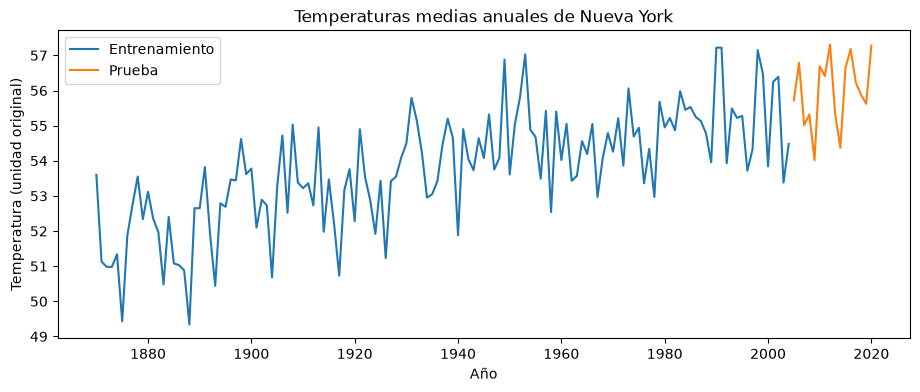

In [3]:
plt.plot(train,label="Entrenamiento");
plt.plot(test,label="Prueba");
plt.title("Temperaturas medias anuales de Nueva York");
plt.xlabel("Año");
plt.ylabel("Temperatura (unidad original)");
plt.legend();
plt.show()

## 3. Prueba de Dickey–Fuller aumentada (ADF)
**Hipótesis nula:** existe raíz unitaria (no estacionariedad). **Alternativa:** la serie es estacionaria en el sentido de la prueba. Se rechaza H₀ si $p<0.05$. La ADF no prueba todas las formas de estacionariedad; también se revisan gráficas y residuos. La diferenciación se hace únicamente sobre entrenamiento.

In [4]:
pruebas=[]
for diferencia in range(4):
    datos=train.diff(diferencia).dropna() if diferencia else train
    resultado=adfuller(datos,autolag="AIC")
    pruebas.append({"d":diferencia,"ADF":resultado[0],"p_valor":resultado[1],"rezagos":resultado[2],"critico_5pct":resultado[4]["5%"]})
    if resultado[1]<0.05: break
adf_tabla=pd.DataFrame(pruebas)
d=int(adf_tabla.iloc[-1]["d"])
print(adf_tabla.to_string(index=False))
print("Diferenciación seleccionada:",d)

 d       ADF      p_valor  rezagos  critico_5pct
 0 -1.717709 4.220121e-01        7      -2.88458
 1 -8.460582 1.571311e-13        6      -2.88458
Diferenciación seleccionada: 1


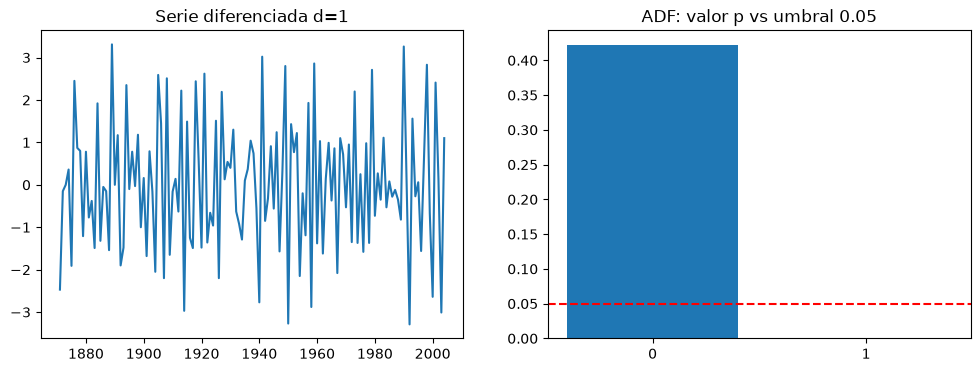

In [5]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(train.diff(d).dropna());
ax[0].set_title(f"Serie diferenciada d={d}")
ax[1].bar(adf_tabla["d"].astype(str),adf_tabla["p_valor"]);ax[1].axhline(0.05,color="red",linestyle="--");
ax[1].set_title("ADF: valor p vs umbral 0.05");
plt.show()

## 4. ACF y PACF
Las funciones de autocorrelación y autocorrelación parcial ayudan a orientar los órdenes $q$ y $p$. La selección definitiva se efectúa mediante AIC sobre los modelos ajustados.

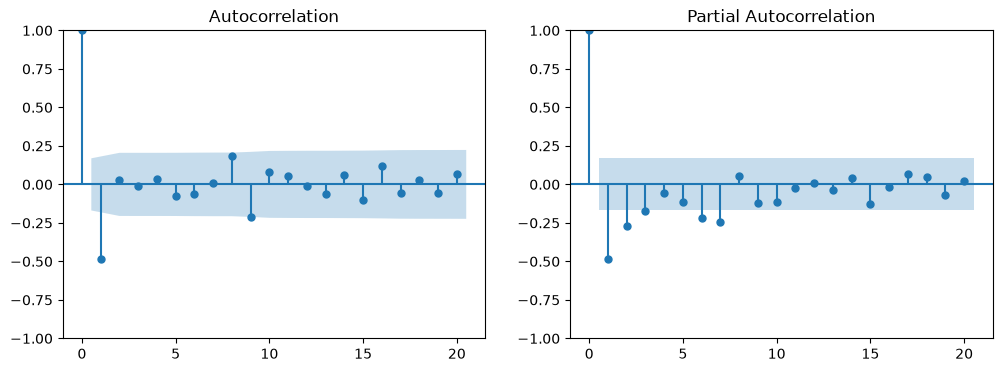

In [6]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
plot_acf(train.diff(d).dropna(),lags=20,ax=ax[0]);
plot_pacf(train.diff(d).dropna(),lags=20,ax=ax[1],method="ywm");
plt.show()

## 5. Búsqueda de modelos ARIMA(p,d,q) mediante AIC
Se comparan 16 combinaciones de $p\in\{0,1,2,3\}$ y $q\in\{0,1,2,3\}$ manteniendo el $d$ determinado por ADF. El mejor AIC es el menor. Se emplea la misma especificación de tendencia para modelos comparables y solo se ajusta entrenamiento.

In [7]:
filas=[]; modelos={}
for p in range(4):
    for q in range(4):
        try:
            modelo=ARIMA(train,order=(p,d,q),trend="n" if d else "c",enforce_stationarity=True,enforce_invertibility=True).fit()
            filas.append({"p":p,"d":d,"q":q,"AIC":modelo.aic,"BIC":modelo.bic})
            modelos[(p,d,q)]=modelo
        except Exception as e: print("No convergió",(p,d,q),str(e)[:80])
comparacion=pd.DataFrame(filas).sort_values("AIC").reset_index(drop=True)
print(comparacion.to_string(index=False))
orden=tuple(int(comparacion.loc[0,k]) for k in ["p","d","q"])
modelo_optimo=modelos[orden]
print("Mejor ARIMA:",orden,"AIC:",modelo_optimo.aic)

 p  d  q        AIC        BIC
 3  1  3 432.550897 452.835776
 0  1  1 433.656509 439.452189
 2  1  3 434.660021 452.047060
 1  1  1 435.230115 443.923635
 0  1  2 435.279607 443.973127
 1  1  3 435.439572 449.928771
 2  1  2 436.813381 451.302580
 2  1  1 436.824147 448.415506
 0  1  3 436.859075 448.450434
 1  1  2 437.025876 448.617235
 3  1  2 438.801199 456.188238
 3  1  1 438.818350 453.307549
 3  1  0 450.831896 462.423255
 2  1  0 453.555588 462.249107
 1  1  0 462.295330 468.091010
 0  1  0 496.475203 499.373043
Mejor ARIMA: (3, 1, 3) AIC: 432.55089695276735


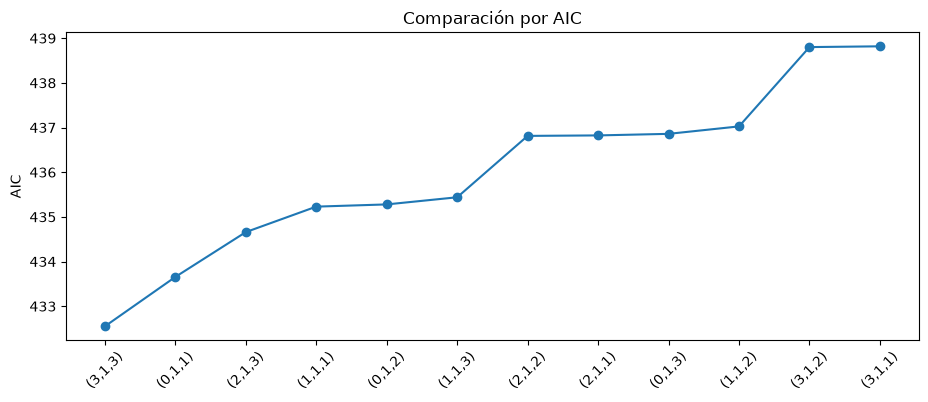

In [8]:
top=comparacion.head(12).copy();
top["Modelo"]=top.apply(lambda x:f"({int(x.p)},{int(x.d)},{int(x.q)})",axis=1)
plt.plot(top["Modelo"],top["AIC"],marker="o");
plt.xticks(rotation=45);
plt.title("Comparación por AIC");
plt.ylabel("AIC");
plt.show()

## 6. Pronóstico puntual y por intervalos (95 %)

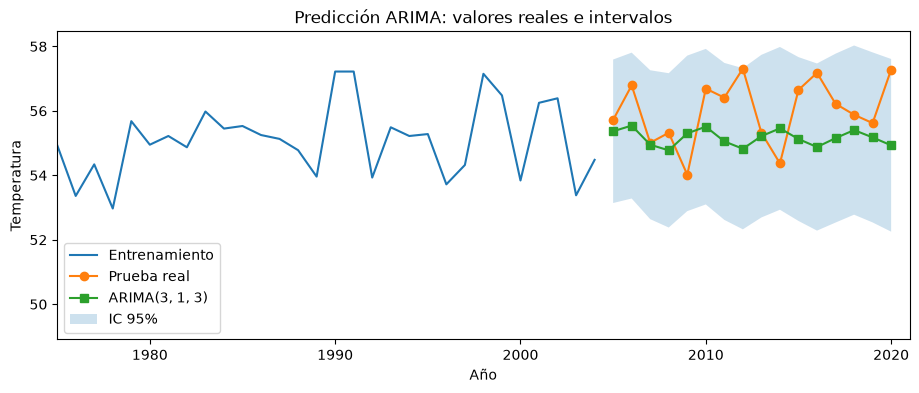

In [9]:
pronostico=modelo_optimo.get_forecast(steps=len(test))
y_pred=pd.Series(np.asarray(pronostico.predicted_mean),index=test.index)
intervalo=np.asarray(pronostico.conf_int(alpha=0.05))
plt.plot(train.index,train,label="Entrenamiento");
plt.plot(test.index,test,"o-",label="Prueba real");
plt.plot(test.index,y_pred,"s-",label=f"ARIMA{orden}")
plt.fill_between(test.index,intervalo[:,0],intervalo[:,1],alpha=.22,label="IC 95%")
plt.xlim(1975,2021);
plt.title("Predicción ARIMA: valores reales e intervalos");
plt.xlabel("Año");
plt.ylabel("Temperatura");
plt.legend();
plt.show()

## 7. Indicadores de error y confiabilidad
Se reportan MAE, RMSE, MAPE (válido porque no hay temperaturas cercanas a cero), sesgo, cobertura empírica de IC 95 % y comparación con un pronóstico ingenuo constante igual al último valor de entrenamiento. Una cobertura del 95 % no está garantizada en solo 16 observaciones. Un AIC bajo no garantiza mejores pronósticos.

In [10]:
errores=test.to_numpy()-y_pred.to_numpy()
mae=mean_absolute_error(test,y_pred);rmse=np.sqrt(mean_squared_error(test,y_pred))
mape=np.mean(np.abs(errores/test.to_numpy()))*100
sesgo=np.mean(errores)
cobertura=np.mean((test.to_numpy()>=intervalo[:,0])&(test.to_numpy()<=intervalo[:,1]))*100
naive=np.repeat(train.iloc[-1],len(test))
mae_naive=mean_absolute_error(test,naive);rmse_naive=np.sqrt(mean_squared_error(test,naive))
metricas=pd.Series({"MAE":mae,"RMSE":rmse,"MAPE (%)":mape,"Sesgo":sesgo,"Cobertura IC95 (%)":cobertura,"MAE ingenuo":mae_naive,"RMSE ingenuo":rmse_naive})
print(metricas.round(4).to_string())
print("Mejora frente a ingenuo (MAE):",round((1-mae/mae_naive)*100,2),"%")

MAE                     1.1166
RMSE                    1.3448
MAPE (%)                1.9799
Sesgo                   0.8205
Cobertura IC95 (%)    100.0000
MAE ingenuo             1.5781
RMSE ingenuo            1.7947
Mejora frente a ingenuo (MAE): 29.25 %


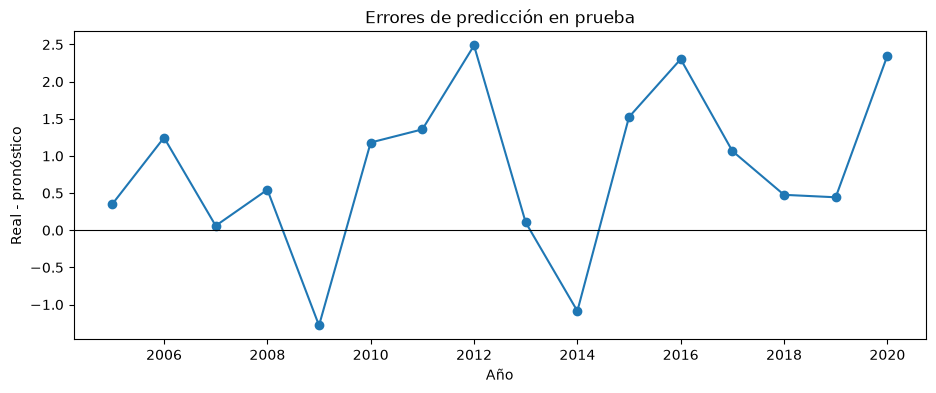

In [11]:
plt.plot(test.index,errores,marker="o");
plt.axhline(0,color="black",linewidth=.8);
plt.title("Errores de predicción en prueba");
plt.xlabel("Año");
plt.ylabel("Real - pronóstico");
plt.show()

## 8. Diagnóstico de residuos y discusión
Se revisan autocorrelación, normalidad visual y heterocedasticidad de residuos. Los resultados de entrenamiento no sustituyen la validación fuera de muestra.

                               SARIMAX Results                                
Dep. Variable:            Temperatura   No. Observations:                  135
Model:                 ARIMA(3, 1, 3)   Log Likelihood                -209.275
Date:                Fri, 23 Oct 2026   AIC                            432.551
Time:                        19:06:16   BIC                            452.836
Sample:                             0   HQIC                           440.794
                                - 135                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2892      0.123      2.353      0.019       0.048       0.530
ar.L2         -0.9205      0.066    -13.933      0.000      -1.050      -0.791
ar.L3          0.1790      0.114      1.574      0.1

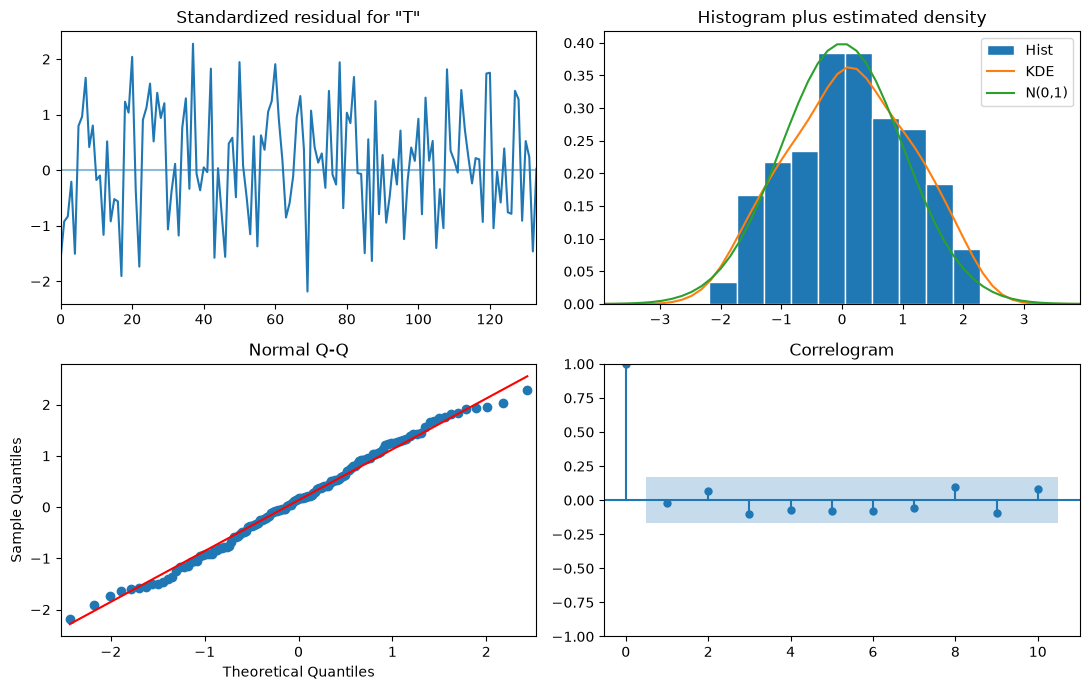

In [12]:
print(modelo_optimo.summary())
modelo_optimo.plot_diagnostics(figsize=(11,7));
plt.tight_layout();
plt.show()

## 9. Conclusiones automáticas y archivos de salida

In [13]:
print(f"ADF: d={d}, valor p={adf_tabla.iloc[-1]['p_valor']:.5f}; ARIMA óptimo={orden}; AIC={modelo_optimo.aic:.2f}")
print(f"Prueba 2005–2020: MAE={mae:.3f}, RMSE={rmse:.3f}, MAPE={mape:.2f}%, cobertura IC95={cobertura:.1f}%")
print("ARIMA supera al ingenuo en MAE:",mae<mae_naive)
print("Conclusión: los pronósticos deben valorarse según error fuera de muestra, comparación ingenua, sesgo y cobertura; no únicamente por AIC.")
comparacion.to_csv("comparacion_arima.csv",index=False)
pd.DataFrame({"Año":test.index,"Real":test.values,"Pronóstico":y_pred.values,"IC inferior":intervalo[:,0],"IC superior":intervalo[:,1],"Error":errores}).to_csv("pronosticos_prueba.csv",index=False)

ADF: d=1, valor p=0.00000; ARIMA óptimo=(3, 1, 3); AIC=432.55
Prueba 2005–2020: MAE=1.117, RMSE=1.345, MAPE=1.98%, cobertura IC95=100.0%
ARIMA supera al ingenuo en MAE: True
Conclusión: los pronósticos deben valorarse según error fuera de muestra, comparación ingenua, sesgo y cobertura; no únicamente por AIC.
